# Embedding magnitude for converted wetland versus two kinds of unconverted wetland, 2017 to 2019

Three groups at each resolution (30m pixels, 300m cells, 3km cells):

A is every positive. B is a random draw of negatives, the same size as A. C is a draw of negatives, the same size as A, whose distance to 2019 development matches A's distribution. B tells us how positives differ from a typical wetland. C tells us how much of that difference is left once you take away "positives sit right next to development".

At 30m a positive is `label == 1` (wetland in 2019, developed by 2024). Negatives are `label == 0`, which includes wetland that went to some other class that isn't developed, since `label.npy` already folds `label_raw == 2` into 0. For cells a positive is `n_developed > 0` and a negative is `n_developed == 0`. Cell distance is `dist_mean`, the mean over the same wetland pixels `emb_mean` averages, so the distance and the embedding describe the same pixels.

C is matched by cutting distance at A's quantiles and drawing as many negatives per bin as A has in that bin, only from negatives inside A's distance range. B and C are drawn independently, so they can share members.

AlphaEarth embeddings should be unit length, so the 30m norms all sit near 1. They spread by a few thousandths, which is well beyond the float16 rounding in `emb.npy` (at most 0.0002 per value), so that spread most likely comes from how the embeddings were quantized upstream, not from anything on the ground. Treat 30m as a sanity check. A cell norm is the norm of a mean of unit vectors, so it drops below 1 when the pixels in the cell point different ways. That makes it a rough measure of how mixed the cell is.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATASETS = {
    "30m": ROOT / "data/arrays_2019_2024",
    "300m": ROOT / "data/cells_2019_2024_300m",
    "3km": ROOT / "data/cells_2019_2024_3km",
}
YEARS = [2017, 2018, 2019]
N_DIM = 64
N_BINS = 50
SEED = 0

manifests = {res: json.loads((d / "manifest.json").read_text()) for res, d in DATASETS.items()}
# the (n, 3, 64) reshape below relies on year major column order
expected_cols = [f"A{i:02d}_{y}" for y in YEARS for i in range(N_DIM)]
for res, m in manifests.items():
    assert m["emb_columns"] == expected_cols, res
    src = m.get("source_manifest", m)
    print(f"{res:>5}  built {m['built_utc']}  commit {m['git_commit'][:7]}  "
          f"pixel arrays built {src['built_utc']} from {src['source_parquet_path']}")

  30m  built 2026-09-04T20:02:03Z  commit 88e677b  pixel arrays built 2026-09-04T20:02:03Z from data/alphaearth_wetland_joined
 300m  built 2026-10-27T21:20:10Z  commit 661cfd1  pixel arrays built 2026-09-04T20:02:03Z from data/alphaearth_wetland_joined
  3km  built 2026-11-03T20:21:41Z  commit 52ebf47  pixel arrays built 2026-09-04T20:02:03Z from data/alphaearth_wetland_joined


In [2]:
def load_resolution(res):
    d = DATASETS[res]
    if res == "30m":
        label = np.load(d / "label.npy") == 1
        dist = np.load(d / "dist.npy")
        emb = np.load(d / "emb.npy", mmap_mode="r")
    else:
        label = np.load(d / "n_developed.npy") > 0
        dist = np.load(d / "dist_mean.npy")
        emb = np.load(d / "emb_mean.npy", mmap_mode="r")
    return label, dist, emb


def sample_groups(label, dist, rng):
    pos = np.flatnonzero(label)
    neg = np.flatnonzero(~label)
    n = pos.size

    b = np.sort(rng.choice(neg, size=n, replace=False))

    # 30m distances are discrete (30, 42.4, 60, ...), so lots of quantile edges tie and get dropped here.
    # Each repeated value then gets its own bin, which is what we want.
    edges = np.unique(np.quantile(dist[pos], np.linspace(0, 1, N_BINS + 1)))
    inner = edges[1:-1]
    pos_bin = np.searchsorted(inner, dist[pos], side="right")
    need = np.bincount(pos_bin, minlength=inner.size + 1)

    neg = neg[(dist[neg] >= edges[0]) & (dist[neg] <= edges[-1])]
    neg_bin = np.searchsorted(inner, dist[neg], side="right")
    c, short = [], 0
    for k, n_k in enumerate(need):
        pool = neg[neg_bin == k]
        if pool.size < n_k:
            short += n_k - pool.size
            c.append(pool)
        else:
            c.append(rng.choice(pool, size=n_k, replace=False))
    c = np.sort(np.concatenate(c))
    return {"A": pos, "B": b, "C": c}, short


def yearly_norms(emb, idx, chunk=100_000):
    # idx is sorted so the 30m memmap reads go forward through the file
    out = np.empty((idx.size, len(YEARS)), dtype=np.float32)
    for s in range(0, idx.size, chunk):
        x = np.asarray(emb[idx[s:s + chunk]], dtype=np.float32).reshape(-1, len(YEARS), N_DIM)
        out[s:s + chunk] = np.linalg.norm(x, axis=2)
    return out

In [3]:
rng = np.random.default_rng(SEED)
groups, norms, dists = {}, {}, {}
for res in DATASETS:
    label, dist, emb = load_resolution(res)
    g, short = sample_groups(label, dist, rng)
    groups[res] = g
    for name, idx in g.items():
        norms[res, name] = yearly_norms(emb, idx)
        dists[res, name] = dist[idx]
    print(f"{res:>5}  positive rate {label.mean():.4%} of {label.size:,}  "
          f"A {g['A'].size:,}  B {g['B'].size:,}  C {g['C'].size:,}  C short by {short:,}")
    del label, dist, emb

  30m  positive rate 0.2799% of 59,267,331  A 165,908  B 165,908  C 165,908  C short by 0


 300m  positive rate 3.0631% of 1,170,463  A 35,852  B 35,852  C 35,852  C short by 0
  3km  positive rate 28.5983% of 23,900  A 6,835  B 6,835  C 5,215  C short by 1,620


## Does C actually match A on distance?

Distance to 2019 development in meters, for each group. C should track A closely, and B should sit much further out.

In [4]:
q = [0.1, 0.25, 0.5, 0.75, 0.9]
rows = []
for (res, name), d in dists.items():
    row = {"resolution": res, "group": name, "n": d.size, "mean": d.mean()}
    row.update({f"p{int(p * 100)}": v for p, v in zip(q, np.quantile(d, q))})
    rows.append(row)
dist_table = pd.DataFrame(rows).set_index(["resolution", "group"])
dist_table.round(1)

n         mean    p10    p25    p50     p75     p90
resolution group                                                          
30m        A      165908    88.199997   30.0   30.0   42.4    94.9   192.1
           B      165908  1589.099976   67.1  201.2  510.0  1321.4  3924.5
           C      165908    93.800003   30.0   30.0   42.4    94.9   192.1
300m       A       35852    77.000000   30.0   32.5   45.8    78.5   139.6
           B       35852  1078.000000   57.2  124.5  330.0   820.9  2094.6
           C       35852    81.300003   30.0   32.5   45.8    78.7   139.6
3km        A        6835   222.199997   43.2   76.3  170.0   294.7   459.9
           B        6835  1236.199951  153.7  252.3  423.0   865.3  2335.3
           C        5215   274.299988   56.7  136.4  223.6   340.4   509.2

## L2 norm of the embedding per year

Mean, median and std of the 64 dimension L2 norm for each group, year and resolution. At 300m and 3km this is the norm of the cell's mean embedding.

In [5]:
rows = []
for (res, name), nv in norms.items():
    for j, y in enumerate(YEARS):
        v = nv[:, j]
        rows.append({"resolution": res, "group": name, "year": y, "n": v.size,
                     "mean": v.mean(), "median": np.median(v), "std": v.std()})
norm_long = pd.DataFrame(rows)

norm_table = (norm_long.pivot_table(index=["resolution", "group"], columns="year",
                                    values=["mean", "median", "std"])
              .reindex(index=pd.MultiIndex.from_product([list(DATASETS), ["A", "B", "C"]])))
norm_table.round(4)

mean                  median                     std                
year      2017    2018    2019    2017    2018    2019    2017    2018    2019
30m  A  0.9915  0.9911  0.9908  0.9931  0.9928  0.9925  0.0072  0.0074  0.0075
     B  0.9946  0.9944  0.9944  0.9958  0.9957  0.9957  0.0059  0.0061  0.0061
     C  0.9908  0.9907  0.9906  0.9925  0.9924  0.9923  0.0075  0.0077  0.0078
300m A  0.9536  0.9517  0.9507  0.9571  0.9553  0.9540  0.0239  0.0249  0.0247
     B  0.9625  0.9618  0.9618  0.9662  0.9657  0.9654  0.0227  0.0233  0.0232
     C  0.9582  0.9572  0.9572  0.9617  0.9608  0.9606  0.0235  0.0243  0.0240
3km  A  0.9040  0.9007  0.9019  0.9062  0.9032  0.9035  0.0270  0.0283  0.0283
     B  0.9211  0.9198  0.9202  0.9220  0.9203  0.9208  0.0297  0.0306  0.0302
     C  0.9173  0.9171  0.9178  0.9175  0.9180  0.9184  0.0295  0.0309  0.0307

## Mean embedding norm per year, by group

One panel per resolution, each with its own y axis because the cell norms sit well below the 30m ones. Points are group means and the bars are plus or minus one std. Groups are nudged apart along x within each year so the bars don't overlap. Each std is about 1.7 to 2.5 times the gap between A and B, so the groups overlap a lot; this shows a shift in the average, not groups that separate cleanly. At 3km, C is 1,620 cells short of A and sits further from development, so the A versus C gap there is not fully distance matched.

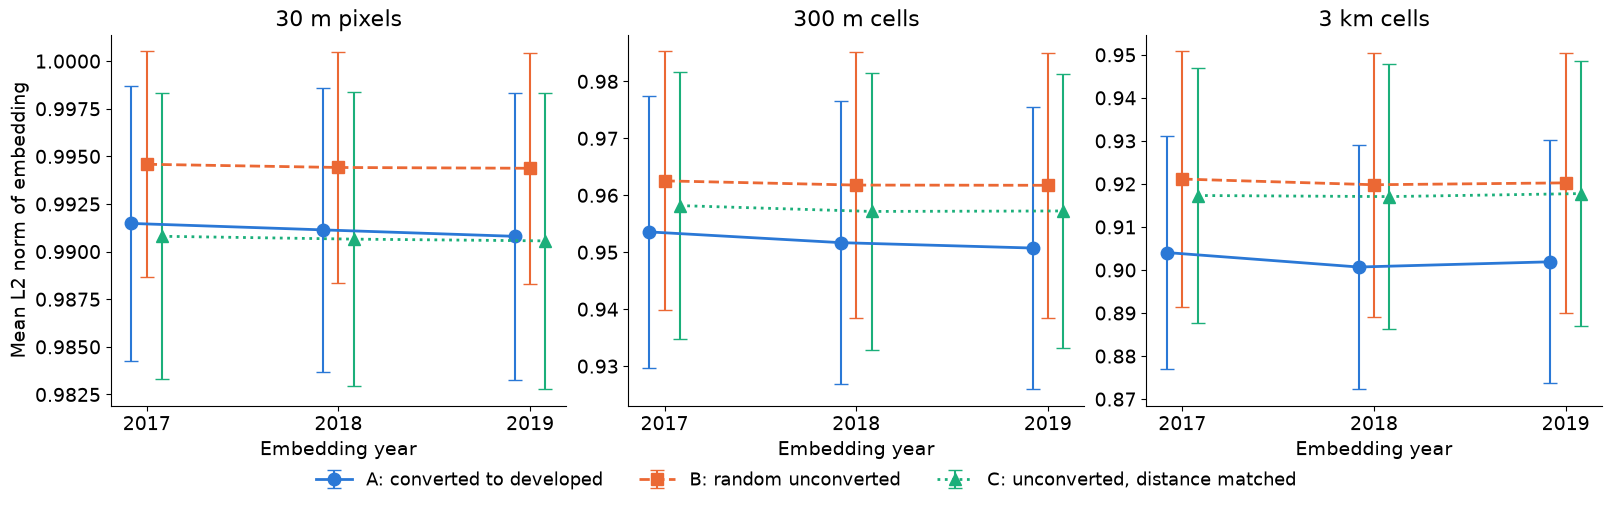

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

FIG_DIR = ROOT / "results/figures/trajectory_analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)

GROUP_STYLE = {
    "A": dict(label="A: converted to developed", color="#2a78d6", marker="o", ls="-"),
    "B": dict(label="B: random unconverted", color="#eb6834", marker="s", ls="--"),
    "C": dict(label="C: unconverted, distance matched", color="#1baf7a", marker="^", ls=":"),
}
PANEL_TITLE = {"30m": "30 m pixels", "300m": "300 m cells", "3km": "3 km cells"}

with plt.rc_context({"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 14, "legend.fontsize": 13}):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for ax, res in zip(axes, DATASETS):
        # nudge groups apart along x so the std bars don't sit on top of each other
        for offset, (name, style) in zip([-0.08, 0, 0.08], GROUP_STYLE.items()):
            m = norm_long.query("resolution == @res and group == @name").sort_values("year")
            ax.errorbar(m["year"] + offset, m["mean"], yerr=m["std"], lw=2, ms=9, capsize=5,
                        elinewidth=1.5, **style)
        ax.set_title(PANEL_TITLE[res])
        ax.set_xticks(YEARS)
        ax.set_xlabel("Embedding year")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Mean L2 norm of embedding")
    # below the panels, since inside any one panel it lands on a line
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
    fig.savefig(FIG_DIR / "embedding_norm_by_group.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

## Did the embedding norm grow or shrink from 2017 to 2019?

Change here is the 2019 norm minus the 2017 norm, so it's signed: negative means the norm shrank. For cells that means the pixels inside the cell became more mixed (their mean embedding got shorter), and positive means they became more alike. At 30m every vector should be unit length, so these differences are tiny and probably reflect how the embeddings were quantized upstream more than change on the ground. Read the 30m row as a check, not a finding.

Rows are resolutions and columns are groups. Each row shares its bins and axes, so read across a row to compare A, B and C. The y axis is percent of the group, because 3km C has fewer cells than A and B. The x axis runs from the row's 0.25th to 99.75th percentile, and anything past either end is piled into the end bins. The dashed line is the group median and the solid gray line is zero.

In [7]:
i17, i19 = YEARS.index(2017), YEARS.index(2019)
changes = {key: nv[:, i19] - nv[:, i17] for key, nv in norms.items()}

rows = []
for (res, name), v in changes.items():
    rows.append({"resolution": res, "group": name, "n": v.size, "mean": v.mean(), "median": np.median(v),
                 "std": v.std(), "p1": np.quantile(v, 0.01), "p99": np.quantile(v, 0.99),
                 "share < 0": (v < 0).mean()})
change_table = pd.DataFrame(rows).set_index(["resolution", "group"])
change_table.round(4)

n    mean  median     std      p1     p99  share < 0
resolution group                                                           
30m        A      165908 -0.0007 -0.0006  0.0046 -0.0130  0.0103     0.5560
           B      165908 -0.0002 -0.0002  0.0040 -0.0098  0.0094     0.5220
           C      165908 -0.0002 -0.0002  0.0044 -0.0113  0.0106     0.5227
300m       A       35852 -0.0028 -0.0025  0.0101 -0.0354  0.0264     0.6729
           B       35852 -0.0008 -0.0009  0.0097 -0.0265  0.0301     0.5624
           C       35852 -0.0009 -0.0011  0.0087 -0.0246  0.0269     0.5845
3km        A        6835 -0.0021 -0.0039  0.0136 -0.0298  0.0470     0.6642
           B        6835 -0.0009 -0.0017  0.0138 -0.0332  0.0449     0.5675
           C        5215  0.0004 -0.0005  0.0145 -0.0357  0.0490     0.5206

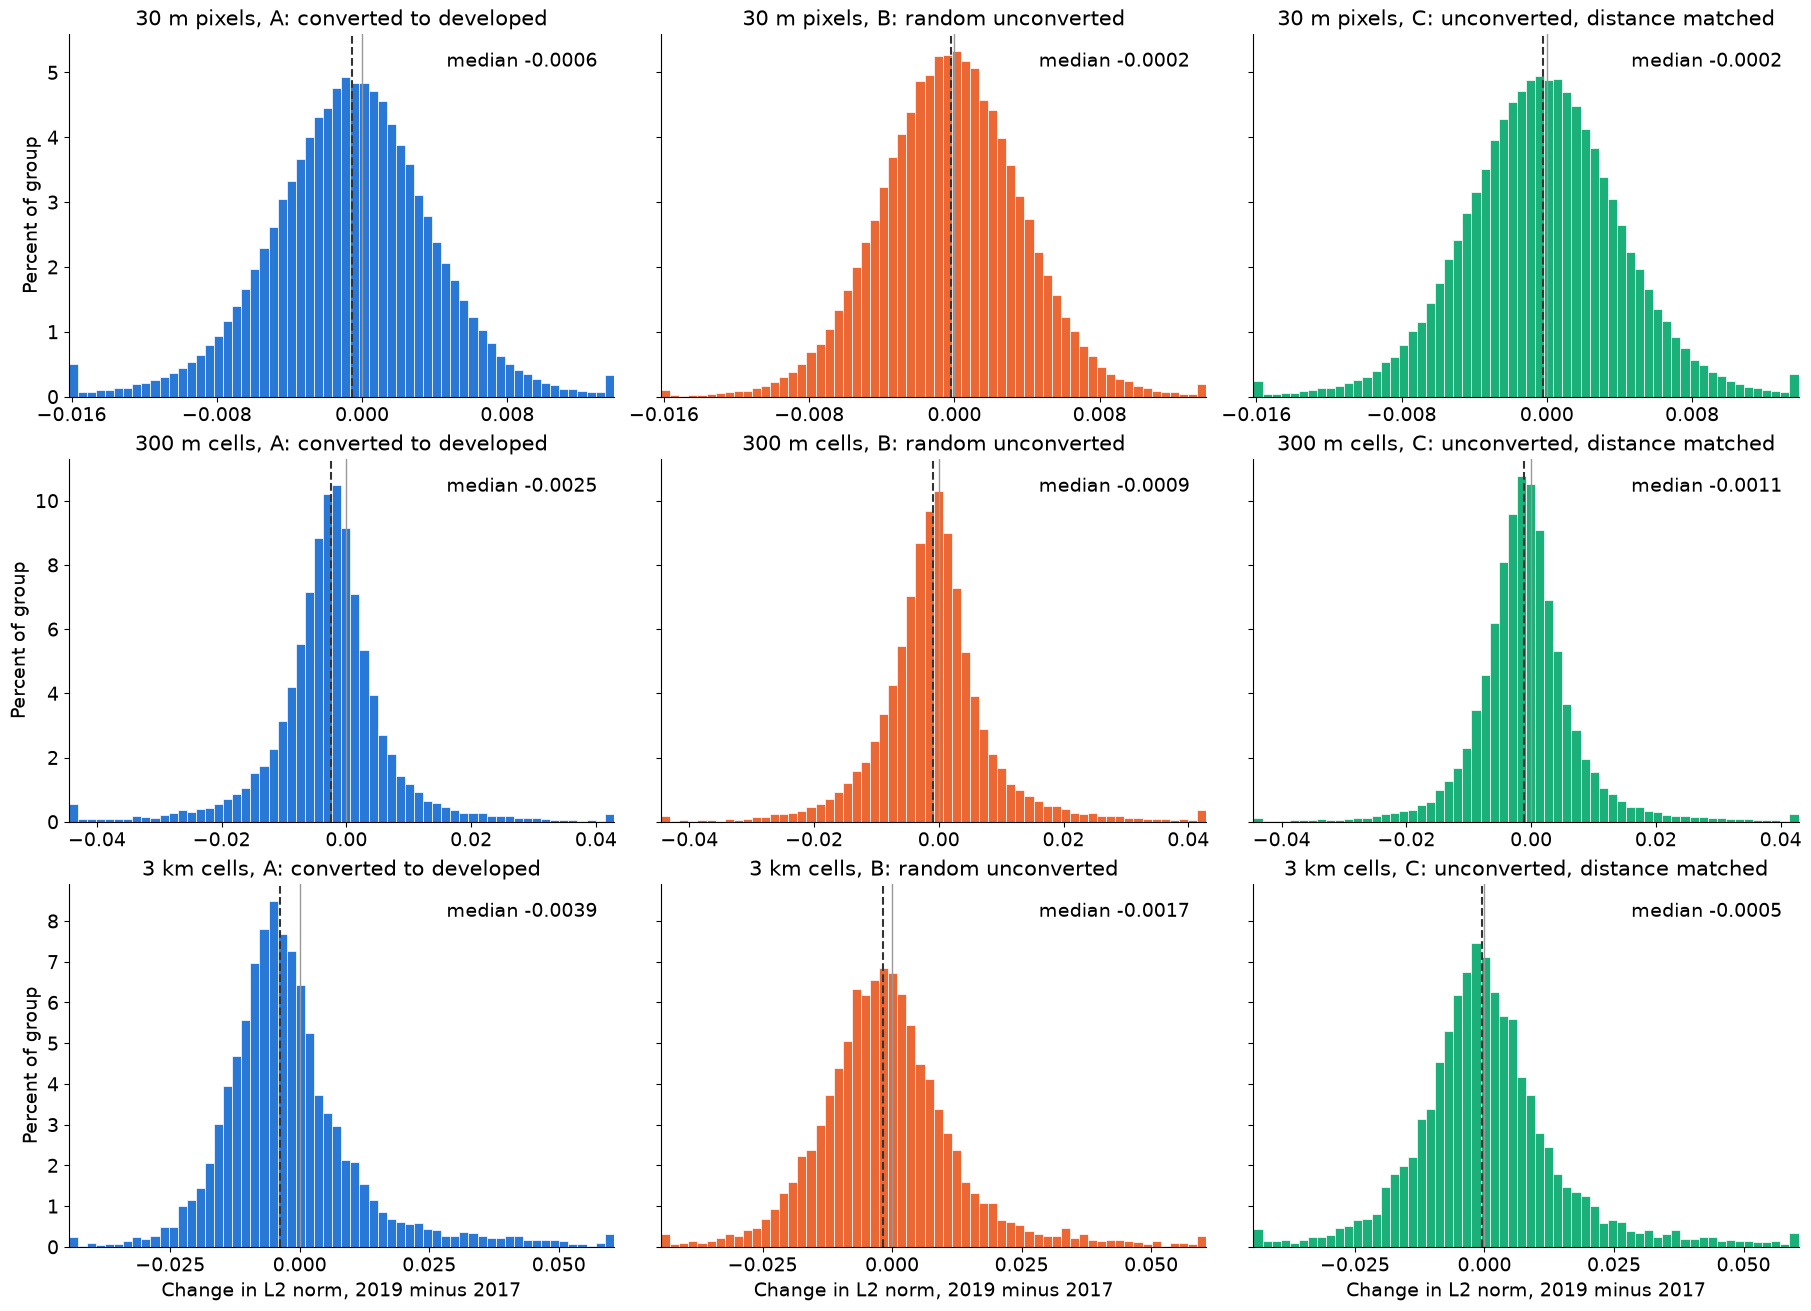

In [8]:
N_HIST_BINS = 60

with plt.rc_context({"font.size": 14, "axes.titlesize": 15, "axes.labelsize": 14}):
    fig, axes = plt.subplots(3, 3, figsize=(18, 13), constrained_layout=True, sharey="row")
    for r, res in enumerate(DATASETS):
        lo, hi = np.quantile(np.concatenate([changes[res, g] for g in GROUP_STYLE]), [0.0025, 0.9975])
        bins = np.linspace(lo, hi, N_HIST_BINS + 1)
        for c, (name, style) in enumerate(GROUP_STYLE.items()):
            ax = axes[r, c]
            v = changes[res, name]
            ax.hist(np.clip(v, lo, hi), bins=bins, weights=np.full(v.size, 100 / v.size),
                    color=style["color"], edgecolor="white", linewidth=0.5)
            ax.axvline(0, color="#999999", lw=1)
            med = np.median(v)
            ax.axvline(med, color="#333333", ls="--", lw=1.5)
            ax.text(0.97, 0.95, f"median {med:+.4f}", transform=ax.transAxes, ha="right", va="top")
            ax.set_xlim(lo, hi)
            ax.xaxis.set_major_locator(MaxNLocator(5))
            ax.set_title(f"{PANEL_TITLE[res]}, {style['label']}")
            ax.spines[["top", "right"]].set_visible(False)
            if r == 2:
                ax.set_xlabel("Change in L2 norm, 2019 minus 2017")
        axes[r, 0].set_ylabel("Percent of group")
    fig.savefig(FIG_DIR / "embedding_norm_change_2017_2019_by_group.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()